# Koordinat valence–arousal item dari tag dan teks

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab05_emosi_sesi/01_koordinat_valence_arousal.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 5 · Kode 5.2.1

**Tujuan belajar**

- Memetakan kata ke koordinat valence–arousal di [-1, 1]² dan menghitung keyakinan (κ).
- Memahami bagaimana bukti, konsistensi, dan cakupan kata memengaruhi κ.
- Menggabungkan sumber tag dan teks dengan rata-rata berbobot keyakinan.

> **Catatan.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

> **Leksikon di sini adalah leksikon mainan** (±36 kata, nilai tiruan pada skala 1–9 ala Warriner). Nilai itu **bukan** data Warriner atau NRC yang sebenarnya, yang berlisensi sendiri dan tidak disertakan. Untuk riset, ganti `LEKSIKON_MENTAH` dengan leksikon asli yang Anda unduh sesuai lisensinya.

## 1. Kode dari buku

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def warriner_to_unit(x):          # Pers. (5-1): skala 1..9 -> [-1, 1]
    return (np.asarray(x, float) - 5.0) / 4.0

def nrc_to_unit(x):               # Pers. (5-1): skala 0..1 -> [-1, 1]
    return 2.0 * np.asarray(x, float) - 1.0

def score_tokens(tokens, lexicon, n_cap=10):
    """lexicon: {kata: (valence, arousal)} sudah di [-1, 1].
    Mengembalikan (v, kappa): rata-rata VA kata tercakup dan keyakinannya."""
    hits = np.array([lexicon[t] for t in tokens if t in lexicon])
    if len(hits) == 0:
        return np.zeros(2), 0.0
    v = hits.mean(axis=0)
    evidence = min(len(hits) / n_cap, 1.0)                  # banyaknya bukti
    spread = hits.std(axis=0).mean() if len(hits) > 1 else 0.5
    consistency = 1.0 - min(spread, 1.0)                    # kesepakatan bukti
    return v, evidence * consistency

def from_tags(tags, lexicon):
    return score_tokens([t.lower().strip() for t in tags], lexicon)

def from_text(text, lexicon):
    tokens = re.findall(r"[a-z']+", text.lower())
    v, kappa = score_tokens(tokens, lexicon)
    coverage = sum(t in lexicon for t in tokens) / max(len(tokens), 1)
    return v, kappa * min(coverage / 0.2, 1.0)              # Pers. (5-2)

def fuse(sources):
    """sources: list[(v, kappa)]. Pers. (5-3): rata-rata berbobot keyakinan,
    keyakinan gabungan 1 - prod(1 - kappa_s)."""
    k = np.array([s[1] for s in sources])
    if k.sum() == 0:
        return np.zeros(2), 0.0                             # cadangan: netral
    v = (k[:, None] * np.array([s[0] for s in sources])).sum(0) / k.sum()
    return np.clip(v, -1, 1), float(1 - np.prod(1 - k))

## 2. Leksikon mainan

In [2]:
# (valence, arousal) pada skala 1..9. NILAI TIRUAN untuk demonstrasi, bukan Warriner asli.
LEKSIKON_MENTAH = {
    "happy": (8.2, 6.5), "joyful": (8.5, 6.2), "cheerful": (8.0, 5.9), "party": (7.9, 7.0),
    "dance": (7.6, 6.9), "energetic": (7.0, 7.8), "thrilling": (7.1, 7.9), "exciting": (7.8, 7.6),
    "love": (8.7, 5.9), "summer": (7.4, 5.2), "morning": (6.5, 4.3),
    "tender": (7.2, 3.5), "peaceful": (7.6, 2.6), "calm": (7.2, 2.1), "relax": (7.4, 2.4),
    "gentle": (7.0, 2.8), "soothing": (7.3, 2.3), "dreamy": (6.8, 3.2),
    "sad": (2.1, 3.9), "lonely": (2.2, 3.6), "gloomy": (2.4, 3.0), "melancholy": (2.8, 3.2),
    "tired": (3.0, 2.6), "bored": (3.2, 2.5), "dark": (3.0, 4.8), "rain": (4.9, 3.8),
    "angry": (2.3, 7.5), "furious": (1.9, 8.0), "tense": (2.9, 7.0), "aggressive": (2.6, 7.6),
    "anxious": (2.7, 6.6), "scary": (2.5, 7.3), "heavy": (3.4, 5.4),
    "night": (5.4, 3.3), "road": (5.5, 4.5), "city": (5.6, 5.0),
}
LEKSIKON = {k: tuple(warriner_to_unit(v)) for k, v in LEKSIKON_MENTAH.items()}

def kuadran(v):
    """0: senang-bergairah, 1: sedih-bergairah, 2: sedih-tenang, 3: senang-tenang."""
    if v[0] >= 0:
        return 0 if v[1] >= 0 else 3
    return 1 if v[1] >= 0 else 2

print("contoh:", {k: tuple(np.round(LEKSIKON[k], 2)) for k in ("calm", "furious", "party")})

contoh: {'calm': (np.float64(0.55), np.float64(-0.72)), 'furious': (np.float64(-0.78), np.float64(0.75)), 'party': (np.float64(0.73), np.float64(0.5))}


## 3. Eksperimen A: tag, teks, dan gabungan

Enam trek contoh. Perhatikan κ untuk tiap sumber, dan apa yang terjadi ketika sumber saling bertentangan atau tidak ada.

In [3]:
trek = {
    "Sunrise Run":   (["happy", "energetic", "summer"], "an upbeat track full of energy and joy for the morning run"),
    "Slow Rain":     (["sad", "rain", "melancholy"], "a gentle and gloomy song for a rainy night, tender and lonely"),
    "Midnight Rage": (["angry", "aggressive", "dark"], "furious heavy riffs, tense and scary from the first bar"),
    "Lake Evening":  (["calm", "peaceful"], "a calm and soothing piece to relax and breathe slowly"),
    "Mixed Signals": (["happy", "sad", "angry", "calm"], "a song about a city road at night"),
    "Tanpa Tag":     ([], "dreamy and gentle sounds, a soothing night to relax"),
}
rows, koordinat = [], {}
for nama, (tags, teks) in trek.items():
    vt, kt = from_tags(tags, LEKSIKON)
    vx, kx = from_text(teks, LEKSIKON)
    vf, kf = fuse([(vt, kt), (vx, kx)])
    koordinat[nama] = vf
    rows.append({"trek": nama, "v_tag": vt[0], "a_tag": vt[1], "k_tag": kt,
                 "v_teks": vx[0], "a_teks": vx[1], "k_teks": kx,
                 "v_gab": vf[0], "a_gab": vf[1], "k_gab": kf, "kuadran": kuadran(vf)})
tabel = pd.DataFrame(rows).set_index("trek")
print(tabel.round(2).to_string())

               v_tag  a_tag  k_tag  v_teks  a_teks  k_teks  v_gab  a_gab  k_gab  kuadran
trek                                                                                    
Sunrise Run     0.63   0.38   0.24    0.38   -0.18    0.02   0.61   0.33   0.26        0
Slow Rain      -0.43  -0.34   0.24   -0.04   -0.44    0.35  -0.20  -0.40   0.51        2
Midnight Rage  -0.59   0.41   0.24   -0.58    0.48    0.32  -0.59   0.45   0.49        1
Lake Evening    0.60  -0.66   0.19    0.58   -0.68    0.29   0.58  -0.68   0.43        3
Mixed Signals  -0.01   0.00   0.15    0.12   -0.18    0.27   0.07  -0.12   0.38        3
Tanpa Tag       0.00   0.00   0.00    0.44   -0.55    0.43   0.44  -0.55   0.43        3


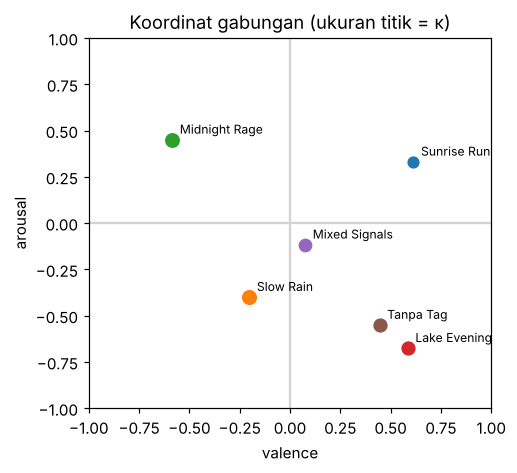

In [4]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.axhline(0, c="lightgray"); ax.axvline(0, c="lightgray")
for nama, v in koordinat.items():
    ax.scatter(*v, s=60 * (0.3 + tabel.loc[nama, "k_gab"] * 2))
    ax.annotate(nama, v, textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set(xlim=(-1, 1), ylim=(-1, 1), xlabel="valence", ylabel="arousal",
       title="Koordinat gabungan (ukuran titik = κ)")
fig.tight_layout()

# klaim yang diuji: trek koheren memiliki κ gabungan lebih tinggi daripada trek yang tags-nya bertentangan
assert tabel.loc["Midnight Rage", "k_gab"] > tabel.loc["Mixed Signals", "k_gab"]
assert tabel.loc["Tanpa Tag", "k_tag"] == 0.0       # tanpa tag: tidak ada bukti dari sumber tag

**Interpretasi.** Trek yang tag-nya sepakat (Midnight Rage, Lake Evening) memiliki koordinat yang jelas dan κ lebih besar. *Mixed Signals* memuat tag yang saling bertentangan sehingga rata-ratanya mendekati pusat dan κ-nya rendah. Pada *Tanpa Tag* sumber tag nol, tetapi sumber teks menutupinya. Titik yang kecil pada plot adalah titik yang tidak boleh dipercaya penuh oleh hilir, misalnya oleh re-ranking di notebook berikutnya.

## 4. Eksperimen B: bukti, konsistensi, dan batas n_cap

Pada `score_tokens`, κ = bukti × konsistensi. Bukti naik linier sampai `n_cap` kata. Bagaimana κ berubah bila kita menambah tag yang sejenis, dan bila kita menambah tag yang bertentangan?

In [5]:
tenang = ["calm", "peaceful", "relax", "gentle", "soothing", "dreamy", "tender"]
campur = ["calm", "furious", "happy", "sad", "party", "lonely", "angry", "peaceful"]
rows = []
for k in range(1, 8):
    rows.append({"jumlah_tag": k,
                 "κ (semua tenang)": score_tokens(tenang[:k], LEKSIKON)[1],
                 "κ (campur aduk)": score_tokens(campur[:k], LEKSIKON)[1]})
hasil_k = pd.DataFrame(rows).set_index("jumlah_tag")
print(hasil_k.round(3))
assert (hasil_k["κ (semua tenang)"].iloc[-1] > hasil_k["κ (campur aduk)"].iloc[-1])

            κ (semua tenang)  κ (campur aduk)
jumlah_tag                                   
1                      0.050            0.050
2                      0.189            0.060
3                      0.286            0.102
4                      0.376            0.142
5                      0.472            0.186
6                      0.554            0.227
7                      0.638            0.270


**Interpretasi.** Satu tag mendapat κ rendah karena buktinya sedikit (konsistensi bernilai 0,5 sebagai nilai awal). Tag yang sejenis menaikkan κ. Tag yang saling bertentangan menaikkan bukti tetapi menurunkan konsistensi, sehingga κ-nya tidak naik. Ini sifat yang diinginkan: lebih banyak data tidak otomatis lebih meyakinkan jika datanya saling membantah.

## 5. Eksperimen C: sifat penggabungan

Keyakinan gabungan `1 − ∏(1 − κ_s)` tidak pernah lebih kecil dari κ sumber terbaik, dan bernilai 0 bila semua sumber tidak punya bukti. Uji pada banyak pasangan acak.

In [6]:
rng = np.random.default_rng(0)
ok_maks, ok_nol = True, True
for _ in range(2000):
    s = [(rng.uniform(-1, 1, 2), rng.uniform(0, 1)) for _ in range(rng.integers(1, 4))]
    v, kf = fuse(s)
    ok_maks &= kf >= max(x[1] for x in s) - 1e-12
    assert -1 <= v.min() and v.max() <= 1
print("κ gabungan >= κ terbaik pada 2000 percobaan acak:", ok_maks)
v0, k0 = fuse([(np.array([0.9, 0.9]), 0.0), (np.array([-0.9, 0.1]), 0.0)])
print("tanpa bukti sama sekali ->", v0, k0)
assert ok_maks and k0 == 0.0 and not v0.any()

κ gabungan >= κ terbaik pada 2000 percobaan acak: True
tanpa bukti sama sekali -> [0. 0.] 0.0


## Pertanyaan refleksi

1. Mengapa `spread` diberi nilai 0,5 ketika hanya ada satu kata yang tercakup? Apa akibatnya bila nilainya 0?
2. Ganti `n_cap` menjadi 3 dan 30. Bagaimana κ trek berubah, dan mengapa pengaturan itu bergantung pada panjang tag di dataset Anda?
3. Apa risiko memakai koordinat dari teks ulasan pengguna untuk item musik, dibanding dari tag editorial?